<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/module2/point_operators.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

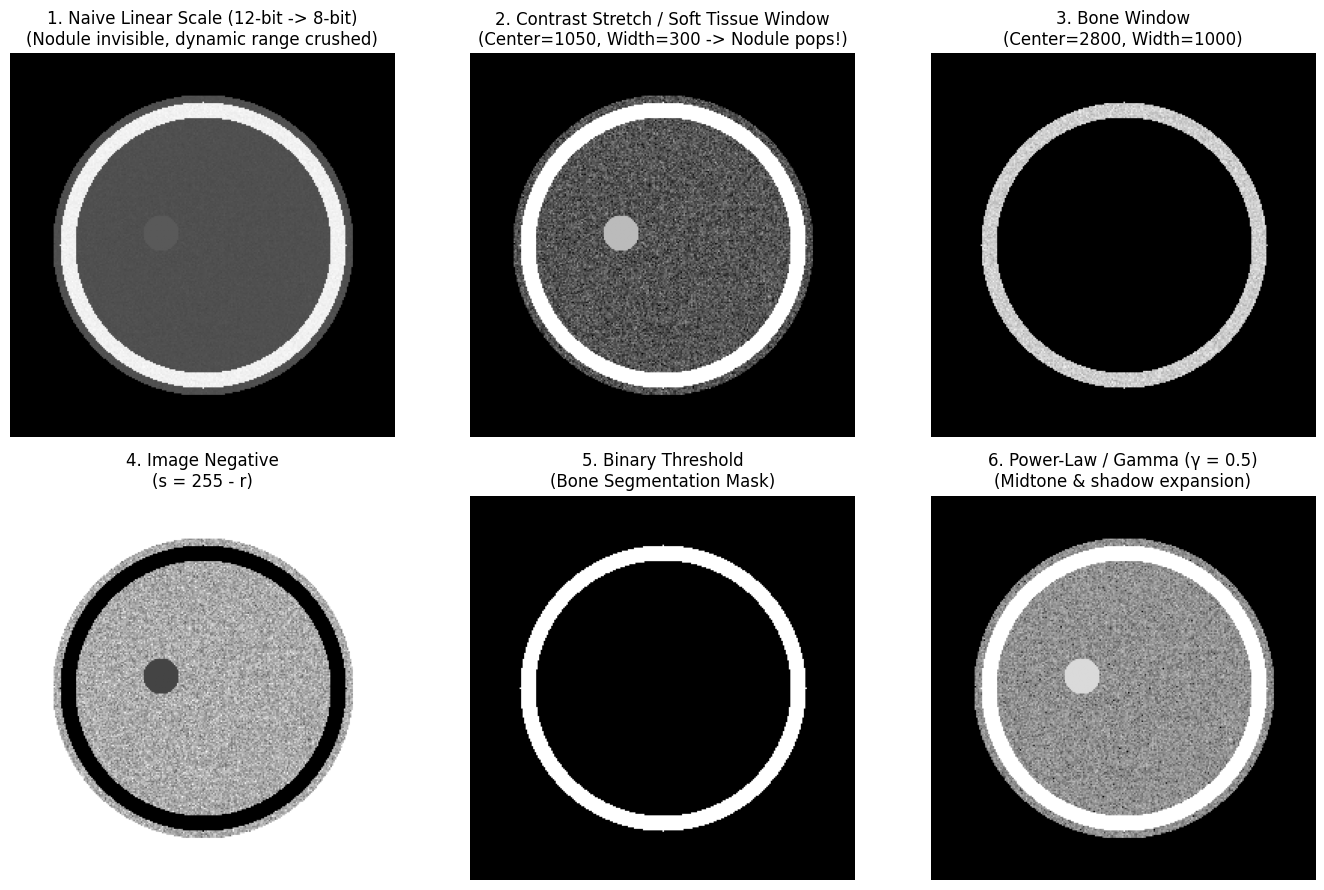

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERATE SYNTHETIC 12-BIT IMAGE (0-4095)
# ==========================================
np.random.seed(42)
h, w = 256, 256
y, x = np.ogrid[:h, :w]
center = (h // 2, w // 2)

# Create a synthetic scan: background air (~0), soft tissue (~1000-1200), bone ring (~3000)
dist_from_center = np.sqrt((x - center[1])**2 + (y - center[0])**2)
synthetic_12bit = np.zeros((h, w), dtype=np.float32)

# Soft tissue background
synthetic_12bit[dist_from_center < 100] = 1000 + np.random.normal(0, 30, (h, w))[dist_from_center < 100]

# High-density "bone" ring
bone_mask = (dist_from_center >= 85) & (dist_from_center <= 95)
synthetic_12bit[bone_mask] = 3000 + np.random.normal(0, 50, (h, w))[bone_mask]

# Subtle "lesion/nodule" (intensity 1120 vs tissue 1000)
lesion_mask = ((x - 100)**2 + (y - 120)**2) < 12**2
synthetic_12bit[lesion_mask] = 1120

# Clip to 12-bit range [0, 4095]
raw_image = np.clip(synthetic_12bit, 0, 4095).astype(np.uint16)

# ==========================================
# 2. DEFINE POINT OPERATOR FUNCTIONS
# ==========================================

def linear_windowing(img, window_center, window_width):
    """
    Medical contrast stretching (windowing):
    Maps [center - width/2, center + width/2] to 8-bit [0, 255].
    """
    lower = window_center - (window_width / 2.0)
    upper = window_center + (window_width / 2.0)

    # Piecewise linear formula: s = T(r)
    stretched = (img.astype(np.float32) - lower) / (upper - lower) * 255.0
    return np.clip(stretched, 0, 255).astype(np.uint8)

def image_negative(img_8bit):
    """Inverts the intensity range: s = (L - 1) - r"""
    return (255 - img_8bit).astype(np.uint8)

def binary_threshold(img_8bit, threshold):
    """Hard cut-off mask: s = 255 if r >= T else 0"""
    return np.where(img_8bit >= threshold, 255, 0).astype(np.uint8)

def gamma_correction(img_8bit, gamma=1.0):
    """Power-law transform: s = c * r^gamma"""
    normalized = img_8bit / 255.0
    corrected = np.power(normalized, gamma) * 255.0
    return np.clip(corrected, 0, 255).astype(np.uint8)

# ==========================================
# 3. APPLY OPERATORS
# ==========================================

# A. Direct 12-bit to 8-bit naive scale (crushes contrast)
naive_display = (raw_image / 4095.0 * 255.0).astype(np.uint8)

# B. Soft Tissue Window: Center = 1050, Width = 300 (Reveals the hidden nodule!)
soft_tissue = linear_windowing(raw_image, window_center=1050, window_width=300)

# C. Bone Window: Center = 2800, Width = 1000
bone_window = linear_windowing(raw_image, window_center=2800, window_width=1000)

# D. Image Negative applied to the soft tissue view
negative = image_negative(soft_tissue)

# E. Thresholding to isolate high-density bone
bone_segmented = binary_threshold(bone_window, threshold=128)

# F. Gamma Correction on soft tissue (Gamma = 0.5 expands dark/shadow details)
gamma_exp = gamma_correction(soft_tissue, gamma=0.5)

# ==========================================
# 4. VISUALIZATION
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

axes[0, 0].imshow(naive_display, cmap='gray')
axes[0, 0].set_title("1. Naive Linear Scale (12-bit -> 8-bit)\n(Nodule invisible, dynamic range crushed)")

axes[0, 1].imshow(soft_tissue, cmap='gray')
axes[0, 1].set_title("2. Contrast Stretch / Soft Tissue Window\n(Center=1050, Width=300 -> Nodule pops!)")

axes[0, 2].imshow(bone_window, cmap='gray')
axes[0, 2].set_title("3. Bone Window\n(Center=2800, Width=1000)")

axes[1, 0].imshow(negative, cmap='gray')
axes[1, 0].set_title("4. Image Negative\n(s = 255 - r)")

axes[1, 1].imshow(bone_segmented, cmap='gray')
axes[1, 1].set_title("5. Binary Threshold\n(Bone Segmentation Mask)")

axes[1, 2].imshow(gamma_exp, cmap='gray')
axes[1, 2].set_title("6. Power-Law / Gamma (γ = 0.5)\n(Midtone & shadow expansion)")

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.show()